In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

Libraries imported successfully!
/kaggle/input/datasets/whofrehat/auto-mpg-raw-dataset/auto-mpg.csv


In [2]:
# Load the raw dataset

from pathlib import Path

filename = "auto-mpg.csv"
file_path = Path(filename)

if not file_path.exists():
    folder = Path("/kaggle/input")
    file_path = next(folder.rglob(filename))

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head(10))

Dataset loaded successfully!
Dataset Shape: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino
5,15.0,8,429.0,198,4341,10.0,70,1,ford galaxie 500
6,14.0,8,454.0,220,4354,9.0,70,1,chevrolet impala
7,14.0,8,440.0,215,4312,8.5,70,1,plymouth fury iii
8,14.0,8,455.0,225,4425,10.0,70,1,pontiac catalina
9,15.0,8,390.0,190,3850,8.5,70,1,amc ambassador dpl


In [3]:
# Inspect the dataset

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print("\nInvalid Horsepower Values:")
print(df["horsepower"].value_counts().head(10))
print("Question marks:", (df["horsepower"] == "?").sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    object 
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.1+ KB

Missing Values:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64

Duplicate Rows:
0

Data Types:
mpg             float64
cylinders         int64
displacement    float64
horsepower       object
weight            i

,mpg,cylinders,displacement,weight,acceleration,model year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,5140.000000,24.800000,82.000000,3.000000


In [4]:
# Data Cleaning

# Create a copy of the original dataset
df_clean = df.copy()

# Convert horsepower to numeric
df_clean["horsepower"] = pd.to_numeric(
    df_clean["horsepower"], errors="coerce"
)

print("Missing Values Before Cleaning:")
print(df_clean.isnull().sum())

# Remove rows with missing horsepower
df_clean = df_clean.dropna(subset=["horsepower"])

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Reset the index
df_clean = df_clean.reset_index(drop=True)

print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum())

print("\nOriginal Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nRemoved Rows:", len(df) - len(df_clean))

print("\nHorsepower Data Type:")
print(df_clean["horsepower"].dtype)

Missing Values Before Cleaning:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64

Missing Values After Cleaning:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64

Original Dataset Shape: (398, 9)
Cleaned Dataset Shape: (392, 9)

Removed Rows: 6

Horsepower Data Type:
float64


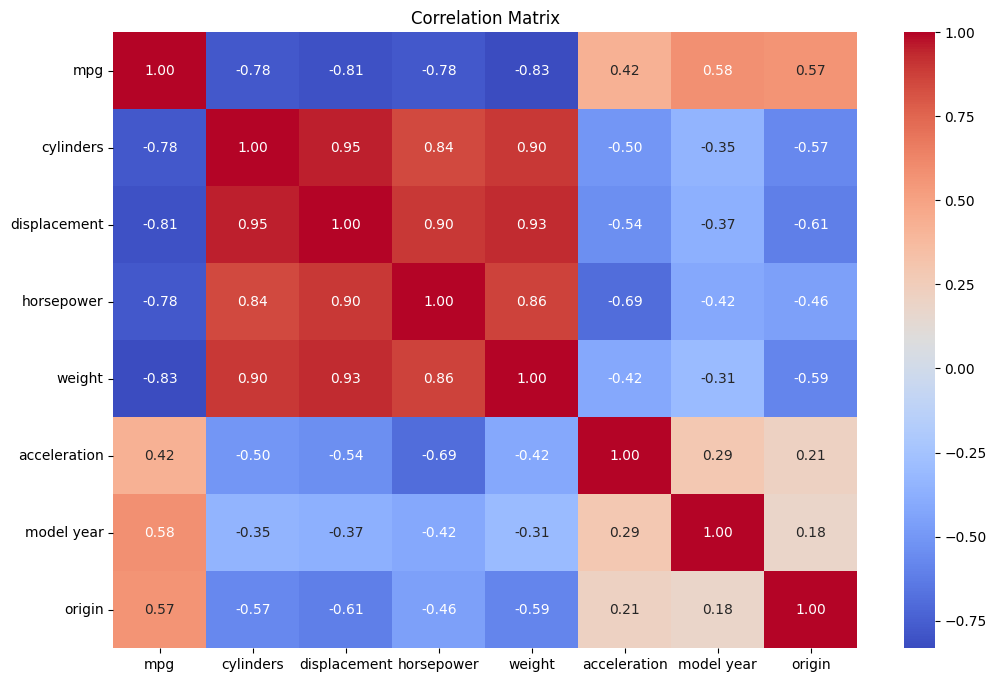

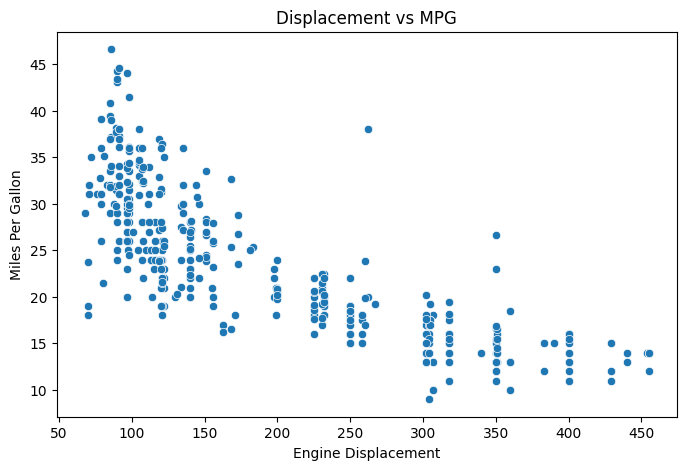

In [5]:
# Exploratory Data Analysis (EDA)

# Select numerical columns
numeric_data = df_clean.select_dtypes(include=np.number)

# Correlation Matrix
plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

# Relationship between displacement and MPG
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="displacement",
    y="mpg"
)

plt.title("Displacement vs MPG")
plt.xlabel("Engine Displacement")
plt.ylabel("Miles Per Gallon")
plt.show()

In [6]:
# Feature Extraction

# Create a copy of the cleaned dataset
df_features = df_clean.copy()

# Extract new features
df_features["power_to_weight"] = (
    df_features["horsepower"] / df_features["weight"]
)

df_features["displacement_per_cylinder"] = (
    df_features["displacement"] / df_features["cylinders"]
)

df_features["weight_per_cylinder"] = (
    df_features["weight"] / df_features["cylinders"]
)

df_features["displacement_squared"] = (
    df_features["displacement"] ** 2
)

print("Feature Extraction completed successfully!")

print("\nBefore Feature Extraction:", df_clean.shape)
print("After Feature Extraction:", df_features.shape)

print("\nExtracted Features:")

display(df_features[[
    "power_to_weight",
    "displacement_per_cylinder",
    "weight_per_cylinder",
    "displacement_squared"
]].head(10))

Feature Extraction completed successfully!

Before Feature Extraction: (392, 9)
After Feature Extraction: (392, 13)

Extracted Features:


,power_to_weight,displacement_per_cylinder,weight_per_cylinder,displacement_squared
0,0.037100,38.375,438.000,94249.0
1,0.044679,43.750,461.625,122500.0
2,0.043655,39.750,429.500,101124.0
3,0.043694,38.000,429.125,92416.0
4,0.040591,37.750,431.125,91204.0
5,0.045612,53.625,542.625,184041.0
6,0.050528,56.750,544.250,206116.0
7,0.049861,55.000,539.000,193600.0
8,0.050847,56.875,553.125,207025.0
9,0.049351,48.750,481.250,152100.0


In [7]:
# Feature Selection

selected_features = [
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model year",
    "power_to_weight",
    "displacement_per_cylinder",
    "weight_per_cylinder",
    "displacement_squared"
]

# Input features
X = df_features[selected_features].copy()

# Target variable
y = df_features["mpg"].copy()

print("Selected Features:")
print(selected_features)

print("\nInput Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nMissing Values:")
print(X.isnull().sum())

print("\nInfinite Values:", np.isinf(X).sum().sum())

display(X.head())

Selected Features:
['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model year', 'power_to_weight', 'displacement_per_cylinder', 'weight_per_cylinder', 'displacement_squared']

Input Features Shape: (392, 10)
Target Shape: (392,)

Missing Values:
cylinders                    0
displacement                 0
horsepower                   0
weight                       0
acceleration                 0
model year                   0
power_to_weight              0
displacement_per_cylinder    0
weight_per_cylinder          0
displacement_squared         0
dtype: int64

Infinite Values: 0


,cylinders,displacement,horsepower,weight,acceleration,model year,power_to_weight,displacement_per_cylinder,weight_per_cylinder,displacement_squared
0,8,307.0,130.0,3504,12.0,70,0.037100,38.375,438.000,94249.0
1,8,350.0,165.0,3693,11.5,70,0.044679,43.750,461.625,122500.0
2,8,318.0,150.0,3436,11.0,70,0.043655,39.750,429.500,101124.0
3,8,304.0,150.0,3433,12.0,70,0.043694,38.000,429.125,92416.0
4,8,302.0,140.0,3449,10.5,70,0.040591,37.750,431.125,91204.0


In [8]:
# Save the processed dataset

from pathlib import Path

processed_data = X.copy()
processed_data["mpg"] = y

# Save on Kaggle or locally
if Path("/kaggle/working").exists():
    output_path = Path("/kaggle/working")
else:
    output_path = Path(".")

file_path = output_path / "processed_auto_mpg.csv"

processed_data.to_csv(file_path, index=False)

print("Processed dataset saved successfully!")
print("File Path:", file_path)
print("Final Dataset Shape:", processed_data.shape)

display(processed_data.head())

Processed dataset saved successfully!
File Path: /kaggle/working/processed_auto_mpg.csv
Final Dataset Shape: (392, 11)


,cylinders,displacement,horsepower,weight,acceleration,model year,power_to_weight,displacement_per_cylinder,weight_per_cylinder,displacement_squared,mpg
0,8,307.0,130.0,3504,12.0,70,0.037100,38.375,438.000,94249.0,18.0
1,8,350.0,165.0,3693,11.5,70,0.044679,43.750,461.625,122500.0,15.0
2,8,318.0,150.0,3436,11.0,70,0.043655,39.750,429.500,101124.0,18.0
3,8,304.0,150.0,3433,12.0,70,0.043694,38.000,429.125,92416.0,16.0
4,8,302.0,140.0,3449,10.5,70,0.040591,37.750,431.125,91204.0,17.0


In [9]:
# Download link for the processed dataset

from IPython.display import FileLink, display

display(FileLink(str(file_path)))

/kaggle/working/processed_auto_mpg.csv